# Kumo Tabular vs tuned baselines on Bank Marketing

Kumo Tabular predicts from labeled rows given as context, with no training. How does it compare to XGBoost and logistic regression, tuned with cross-validation on the same rows, as the number of labeled rows grows?

In [1]:
%pip install -q git+https://github.com/NVIDIA/structured-data-models.git xgboost

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import io, time, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sdm
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
df = pd.read_csv(inner.open("bank-additional/bank-additional-full.csv"), sep=";")

df = df.drop(columns="duration")  # call length, only known after the outcome
df["y"] = (df["y"] == "yes").astype(int)
df.shape, df["y"].mean()

((41188, 20), np.float64(0.11265417111780131))

## Setup
Fixed test set of 4,000 rows. Labeled rows are sampled from the rest. Baselines are tuned with stratified CV on the labeled rows only.

In [3]:
pool, test = train_test_split(df, test_size=4000, stratify=df["y"], random_state=0)

X = pd.get_dummies(df.drop(columns="y"), dtype=float)
X_test = X.loc[test.index]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
kumo = sdm.models.KumoTabular(task="classification", device=device)


def kumo_predict(ctx, seed):
    data = pd.concat([ctx, test], ignore_index=True)
    table = sdm.TableTensor.from_pandas(
        df=data,
        stypes=sdm.infer_stypes(data, overrides={"y": "categorical"}),
        device=device,
    )
    n = len(ctx)
    with torch.amp.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
        probs = kumo(
            x_context=table[:n].drop_columns("y"),
            y_context=table[:n, "y"],
            x_query=table[n:].drop_columns("y"),
            num_estimators=8,
        )
    scores, _ = sdm.evaluation.to_binary_class(probs, table[n:, "y"], positive_class=1)
    return scores.float().cpu().numpy()


def cv_for(y):
    # with ~2 positives at n=20, each fold needs at least one
    k = int(min(5, y.sum(), (y == 0).sum()))
    return StratifiedKFold(n_splits=max(k, 2), shuffle=True, random_state=0)


xgb_space = {
    "n_estimators": [50, 100, 200, 400],
    "max_depth": [2, 3, 4, 6],
    "learning_rate": [0.01, 0.03, 0.1, 0.3],
    "min_child_weight": [0.1, 0.5, 1, 5],
    "subsample": [0.7, 1.0],
    "colsample_bytree": [0.5, 0.8, 1.0],
    "reg_lambda": [0.1, 1, 10],
}


def xgb_default(ctx, seed):
    model = XGBClassifier(random_state=seed)
    model.fit(X.loc[ctx.index], ctx["y"])
    return model.predict_proba(X_test)[:, 1]


def xgb_tuned(ctx, seed):
    search = RandomizedSearchCV(
        XGBClassifier(tree_method="hist", random_state=seed, n_jobs=-1),
        xgb_space, n_iter=25, scoring="roc_auc", cv=cv_for(ctx["y"]), random_state=seed,
    )
    search.fit(X.loc[ctx.index], ctx["y"])
    return search.predict_proba(X_test)[:, 1]


def logreg_tuned(ctx, seed):
    search = GridSearchCV(
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
        {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
        scoring="roc_auc", cv=cv_for(ctx["y"]),
    )
    search.fit(X.loc[ctx.index], ctx["y"])
    return search.predict_proba(X_test)[:, 1]


models = {
    "Kumo Tabular": kumo_predict,
    "XGBoost (tuned)": xgb_tuned,
    "XGBoost (default)": xgb_default,
    "LogReg (tuned)": logreg_tuned,
}


def top_capture(y, p, frac=0.1):
    # share of all "yes" customers found by calling the top 10% scored
    k = int(len(y) * frac)
    return y.values[np.argsort(-p)[:k]].sum() / y.sum()

config.json:   0%|          | 0.00/423 [00:00<?, ?B/s]

large/classifier.pt: reconstructing file:   0%|          |  0.00B /  855MB            

large/classifier.pt: downloading bytes:           |  0.00B            

In [4]:
ctx, _ = train_test_split(pool, train_size=100, stratify=pool["y"], random_state=0)
{name: round(roc_auc_score(test["y"], f(ctx, 0)), 3) for name, f in models.items()}

{'Kumo Tabular': np.float64(0.757),
 'XGBoost (tuned)': np.float64(0.719),
 'XGBoost (default)': np.float64(0.698),
 'LogReg (tuned)': np.float64(0.732)}

## Run
Takes a while because of the tuning (roughly 10-20 min on Colab).

In [5]:
sizes = [20, 50, 100, 500, 1000, 5000]
rows, curves = [], {}

for n in sizes:
    for seed in range(3):
        ctx, _ = train_test_split(pool, train_size=n, stratify=pool["y"], random_state=seed)
        for name, f in models.items():
            start = time.perf_counter()
            p = f(ctx, seed)
            seconds = time.perf_counter() - start
            rows.append({
                "n": n, "seed": seed, "model": name, "seconds": seconds,
                "auc": roc_auc_score(test["y"], p),
                "top10": top_capture(test["y"], p),
            })
            if n == 100 and seed == 0:
                curves[name] = p
    print(n, "done")

results = pd.DataFrame(rows)

20 done
50 done
100 done
500 done
1000 done
5000 done


## Results

In [6]:
auc = results.groupby(["n", "model"])["auc"].mean().unstack()[list(models)]
auc.round(3)

model,Kumo Tabular,XGBoost (tuned),XGBoost (default),LogReg (tuned)
n,,,,
20,0.668,0.575,0.500,0.666
50,0.731,0.723,0.686,0.719
100,0.735,0.711,0.708,0.740
500,0.770,0.750,0.717,0.756
1000,0.776,0.769,0.720,0.760
5000,0.786,0.778,0.738,0.772


In [7]:
baselines = auc.drop(columns="Kumo Tabular")
pd.DataFrame({
    "Kumo": auc["Kumo Tabular"],
    "best baseline": baselines.max(axis=1),
    "best baseline model": baselines.idxmax(axis=1),
    "gap": auc["Kumo Tabular"] - baselines.max(axis=1),
}).round(3)

,Kumo,best baseline,best baseline model,gap
n,,,,
20,0.668,0.666,LogReg (tuned),0.002
50,0.731,0.723,XGBoost (tuned),0.008
100,0.735,0.740,LogReg (tuned),-0.005
500,0.770,0.756,LogReg (tuned),0.013
1000,0.776,0.769,XGBoost (tuned),0.007
5000,0.786,0.778,XGBoost (tuned),0.009


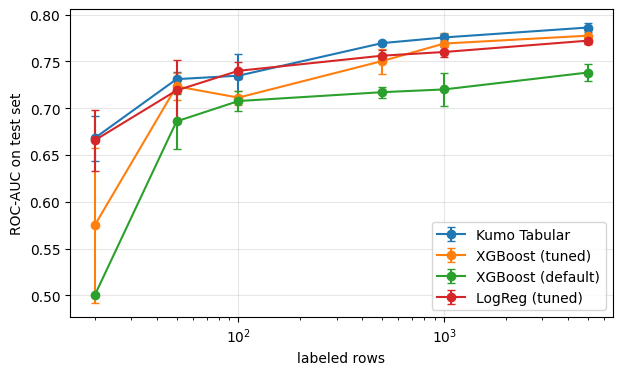

In [8]:
def plot_metric(metric, ylabel, logy=False):
    summary = results.groupby(["n", "model"])[metric].agg(["mean", "std"]).reset_index()
    fig, ax = plt.subplots(figsize=(7, 4))
    for name in models:
        g = summary[summary["model"] == name]
        ax.errorbar(g["n"], g["mean"], yerr=g["std"], marker="o", capsize=3, label=name)
    ax.set_xscale("log")
    ax.set_xlabel("labeled rows")
    ax.set_ylabel(ylabel)
    if logy:
        ax.set_yscale("log")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.show()

plot_metric("auc", "ROC-AUC on test set")

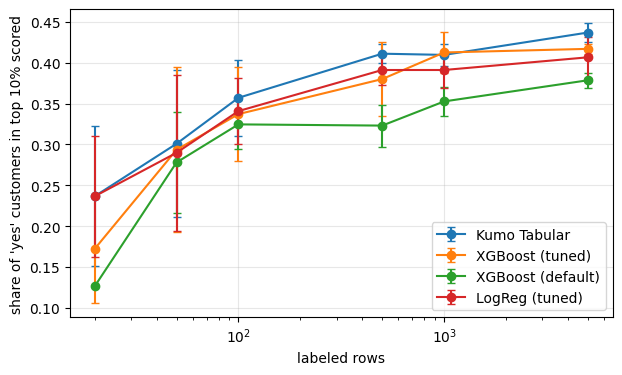

In [9]:
plot_metric("top10", "share of 'yes' customers in top 10% scored")

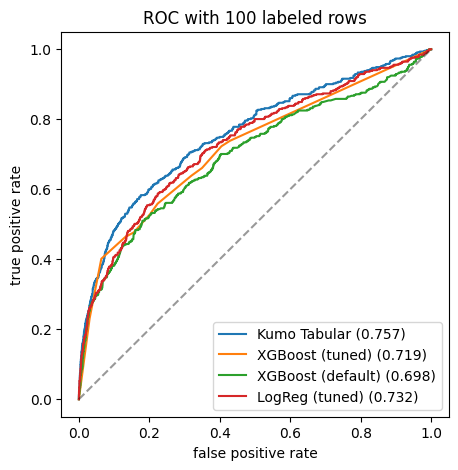

In [10]:
fig, ax = plt.subplots(figsize=(5, 5))
for name, p in curves.items():
    fpr, tpr, _ = roc_curve(test["y"], p)
    ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(test['y'], p):.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("ROC with 100 labeled rows")
ax.legend()
plt.show()

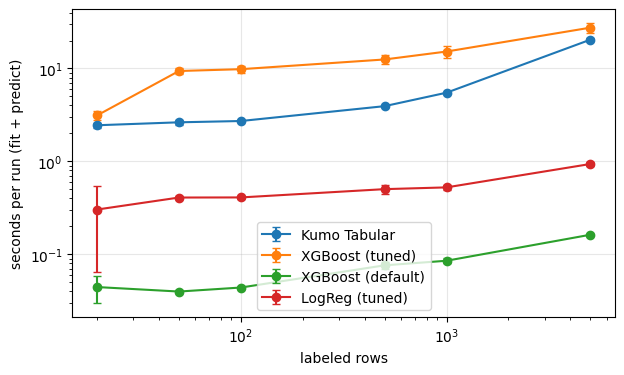

In [11]:
plot_metric("seconds", "seconds per run (fit + predict)", logy=True)

## Notes